# Data import
What datasets are you using, later explain the variables a little bit more


In [2]:
import pandas as pd
import os
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder


In [3]:
print("Current Working Directory:", os.getcwd())


# Load the datasets
mat_data = pd.read_csv('../../student/student-mat.csv', sep=';')
por_data = pd.read_csv('../../student/student-por.csv', sep=';')

# View the first few rows
print(mat_data.head())
print(por_data.head())

Current Working Directory: c:\Users\ivoga\Documents\Git local repositories\projekt-R\testiranje\klasifikacijski_modeli\combined
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5       

In [4]:
print(mat_data.describe())
print(por_data.describe())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

# Encoding the data
binary features are encoded using label encoding (0 and 1), 
while for categorical features one-hot encoding is used.
As for the numerical features, they are normilized using min-max scaling.

In [5]:
# combine the data
combined_data = pd.concat([mat_data, por_data], ignore_index=True)

In [6]:
# encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    combined_data[feature] = label_encoder.fit_transform(combined_data[feature])


# one-hot endocing the categorical features
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']

combined_data = pd.get_dummies(combined_data, columns=categorical_features, drop_first=True)

# normalizing numeric features using min-max scaling
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()
combined_data[numeric_features] = scaler.fit_transform(combined_data[numeric_features])



# Binary Classification
Predict whether G3 is above or below a threshold (e.g., 0.5)


In [7]:
# Create a binary target variable
combined_data['G3_binary'] = (combined_data['G3'] > 0.5).astype(int)

# Define features and target
X_binary = combined_data.drop(columns=['G3', 'G3_binary'])
y_binary = combined_data['G3_binary']

In [8]:
# Split the data
X_train_binary, X_test_binary, y_train_binary, y_test_binary = train_test_split(
    X_binary, y_binary, test_size=0.2, random_state=42
)


In [9]:
# Train Random Forest Classifier
rf_binary = RandomForestClassifier(random_state=42)
rf_binary.fit(X_train_binary, y_train_binary)

RandomForestClassifier(random_state=42)

Binary Classification Results:
Accuracy: 0.9425837320574163
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93        87
           1       0.94      0.96      0.95       122

    accuracy                           0.94       209
   macro avg       0.94      0.94      0.94       209
weighted avg       0.94      0.94      0.94       209

Confusion Matrix:
[[ 80   7]
 [  5 117]]


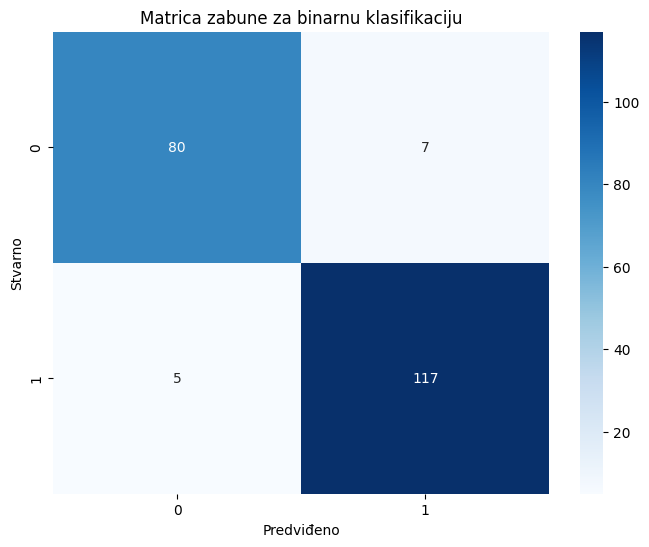

In [10]:
# Predict and evaluate
y_pred_binary = rf_binary.predict(X_test_binary)
print("Binary Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_binary, y_pred_binary)}")
print("Classification Report:")
print(classification_report(y_test_binary, y_pred_binary))
print("Confusion Matrix:")
print(confusion_matrix(y_test_binary, y_pred_binary))

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_binary, y_pred_binary), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predviđeno")
plt.ylabel("Stvarno")
plt.title("Matrica zabune za binarnu klasifikaciju")
plt.show()

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, log_loss
from sklearn.preprocessing import label_binarize

# Binary Classification
print("Binary Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_binary, y_pred_binary)}")
print(f"Precision: {precision_score(y_test_binary, y_pred_binary)}")
print(f"Recall: {recall_score(y_test_binary, y_pred_binary)}")
print(f"F1-Score: {f1_score(y_test_binary, y_pred_binary)}")
print(f"AUC-ROC: {roc_auc_score(y_test_binary, y_pred_binary)}")

# Log-Loss (use predicted probabilities)
y_pred_prob_binary = rf_binary.predict_proba(X_test_binary)[:, 1]
print(f"Log-Loss: {log_loss(y_test_binary, y_pred_prob_binary)}")


Binary Classification Results:
Accuracy: 0.9425837320574163
Precision: 0.9435483870967742
Recall: 0.9590163934426229
F1-Score: 0.9512195121951219
AUC-ROC: 0.9392783116638402
Log-Loss: 0.2262969046319785


# 5-Level Classification
Categorize G3 into 5 performance levels

In [12]:
# Create 5 levels for the target variable (G3)
combined_data['G3_5_levels'] = pd.cut(
    combined_data['G3'],
    bins=5,
    labels=[0, 1, 2, 3, 4],
    include_lowest=True
)

In [13]:
# Define features and target
X_5_levels = combined_data.drop(columns=['G3', 'G3_binary', 'G3_5_levels'])
y_5_levels = combined_data['G3_5_levels']

In [14]:
# Split the data
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(
    X_5_levels, y_5_levels, test_size=0.2, random_state=42
)

In [15]:
# Train Random Forest Classifier
rf_5_levels = RandomForestClassifier(random_state=42)
rf_5_levels.fit(X_train_5, y_train_5)

RandomForestClassifier(random_state=42)

In [16]:
# Predict and evaluate
y_pred_5 = rf_5_levels.predict(X_test_5)
print("5-Level Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_5, y_pred_5)}")
print("Classification Report:")
print(classification_report(y_test_5, y_pred_5))
print("Confusion Matrix:")
print(confusion_matrix(y_test_5, y_pred_5))

5-Level Classification Results:
Accuracy: 0.7894736842105263
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.42      0.56        12
           1       0.89      0.57      0.70        28
           2       0.76      0.89      0.82        94
           3       0.81      0.84      0.82        64
           4       0.86      0.55      0.67        11

    accuracy                           0.79       209
   macro avg       0.83      0.65      0.71       209
weighted avg       0.80      0.79      0.78       209

Confusion Matrix:
[[ 5  1  6  0  0]
 [ 0 16 12  0  0]
 [ 1  1 84  8  0]
 [ 0  0  9 54  1]
 [ 0  0  0  5  6]]


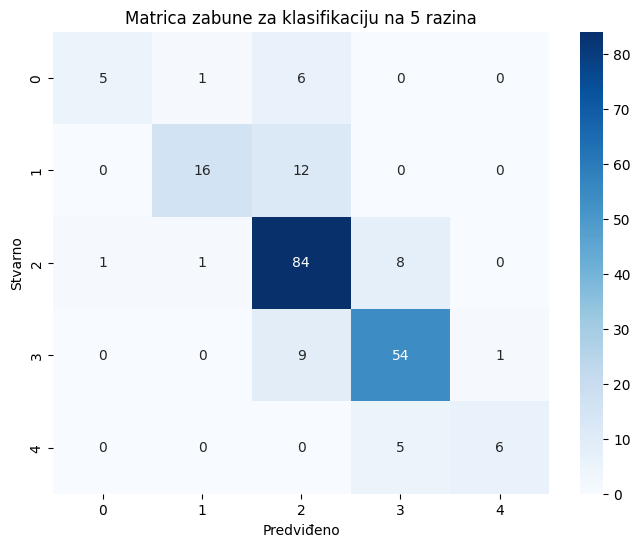

In [20]:
# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_5, y_pred_5), annot=True, fmt="d", cmap="Blues", 
            xticklabels=[0, 1, 2, 3, 4], yticklabels=[0, 1, 2, 3, 4])
plt.xlabel("Predviđeno")
plt.ylabel("Stvarno")
plt.title("Matrica zabune za klasifikaciju na 5 razina")
plt.show()

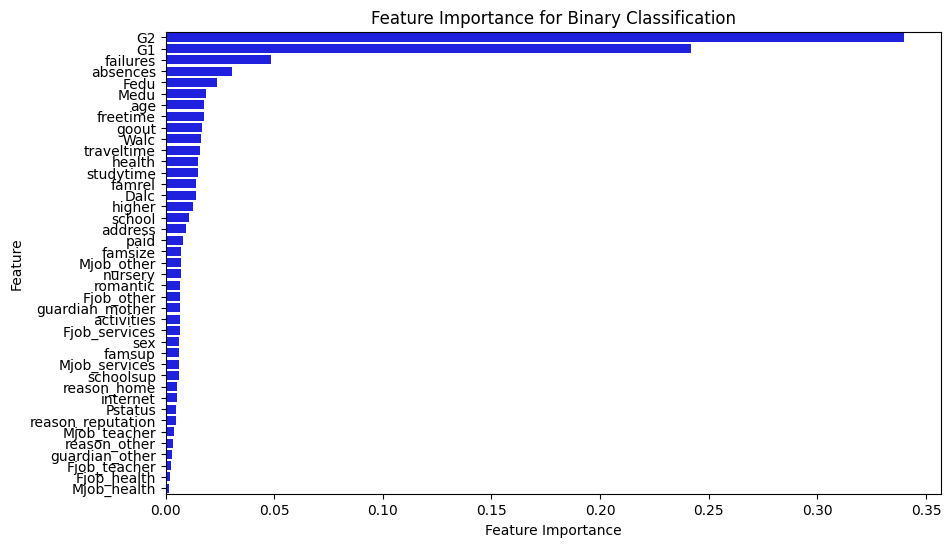

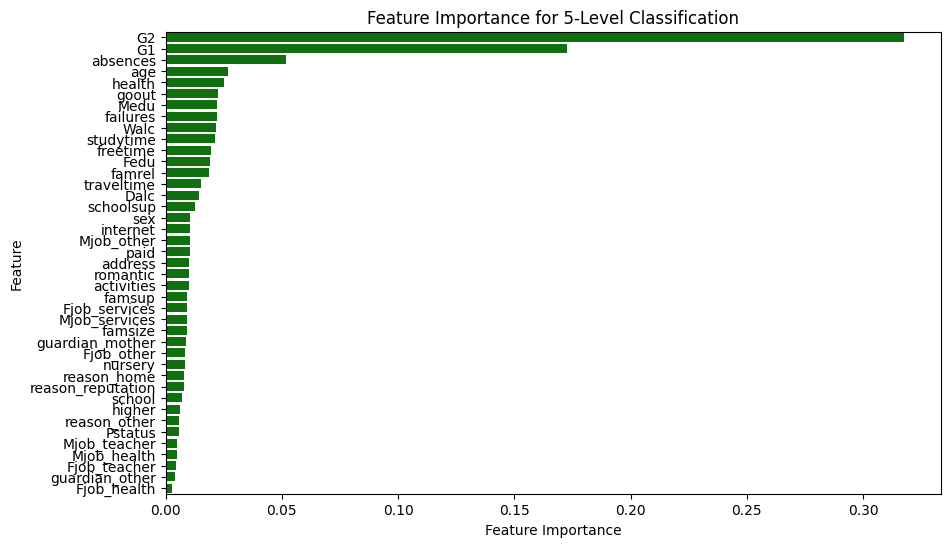

In [18]:
# Feature importance visualization for binary classification
importances_binary = rf_binary.feature_importances_
feature_names_binary = X_binary.columns

# Sorting the feature importances in descending order
sorted_indices_binary = importances_binary.argsort()[::-1]
sorted_importances_binary = importances_binary[sorted_indices_binary]
sorted_feature_names_binary = feature_names_binary[sorted_indices_binary]

plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_importances_binary, y=sorted_feature_names_binary, color="b")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance for Binary Classification")
plt.show()

# Feature importance visualization for 5-level classification
importances_5_levels = rf_5_levels.feature_importances_
feature_names_5_levels = X_5_levels.columns

# Sorting the feature importances in descending order
sorted_indices_5_levels = importances_5_levels.argsort()[::-1]
sorted_importances_5_levels = importances_5_levels[sorted_indices_5_levels]
sorted_feature_names_5_levels = feature_names_5_levels[sorted_indices_5_levels]

plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_importances_5_levels, y=sorted_feature_names_5_levels, color="g")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance for 5-Level Classification")
plt.show()

In [19]:
# 5-Level Classification
# Convert the labels to a binary format for AUC-ROC
y_test_5_bin = label_binarize(y_test_5, classes=[0, 1, 2, 3, 4])
y_pred_5_bin = label_binarize(y_pred_5, classes=[0, 1, 2, 3, 4])

print("5-Level Classification Results:")
print(f"Accuracy: {accuracy_score(y_test_5, y_pred_5)}")
print(f"Precision (Macro): {precision_score(y_test_5, y_pred_5, average='macro')}")
print(f"Recall (Macro): {recall_score(y_test_5, y_pred_5, average='macro')}")
print(f"F1-Score (Macro): {f1_score(y_test_5, y_pred_5, average='macro')}")
print(f"AUC-ROC (Micro): {roc_auc_score(y_test_5_bin, y_pred_5_bin, average='micro', multi_class='ovr')}")

# Log-Loss (use predicted probabilities)
y_pred_prob_5 = rf_5_levels.predict_proba(X_test_5)
log_loss_5 = log_loss(y_test_5, y_pred_prob_5)
print(f"Log-Loss: {log_loss_5}")

5-Level Classification Results:
Accuracy: 0.7894736842105263
Precision (Macro): 0.8284183970751136
Recall (Macro): 0.6541833609652759
F1-Score (Macro): 0.7123628144346494
AUC-ROC (Micro): 0.868421052631579
Log-Loss: 0.5559213185350103
